# PyTorch 입문 — Compose · MNIST · DataLoader

`__call__` transform, `Compose`, MNIST, 배치 shape, 한 장 그리기를 연습합니다.  
이론 복습: [`../session05.md`](../session05.md)

> **이 노트북이 하는 일**  
> `adder`의 `__call__` → `Compose` → MNIST(`CenterCrop`+`ToTensor`) → shape → DataLoader → `imshow`.

환경: `torch-env` 커널을 쓰는 것을 권장합니다.  
첫 실행 시 MNIST 다운로드에 네트워크가 필요합니다.

## 1. import

`torchvision.transforms`로 전처리 파이프라인을 만듭니다.

In [10]:
import torch
from torch.utils.data import Dataset, DataLoader # Dataset: 데이터셋, DataLoader: 데이터 로더
from torchvision import datasets, transforms # datasets: MNIST 데이터셋, transforms: 전처리 파이프라인
import matplotlib.pyplot as plt # 그래프 그리기

## 2. session04 복습 — hi_set · scaling

Dataset 본편은 session04입니다. 여기서는 `__call__`·Compose 연습용으로만 둡니다.

In [11]:
class hi_set(Dataset):
    def __init__(self, length=10, transform=None):
        torch.manual_seed(101) # 랜덤 시드 설정. 랜덤 시드를 설정하면 동일한 랜덤 시드를 사용하여 동일한 결과를 얻을 수 있습니다.
        self.x = 10 * torch.ones(length, 2) # tensor 당 1의 값을 가진 length x 2 행렬을 생성. 10을 곱합니다.
        self.y = torch.ones(length, 1) # tensor 당 1의 값을 가진 length x 1 행렬을 생성.
        self.transform = transform # transform을 적용. 전처리 함수를 적용
        self.len = length # 데이터셋의 길이를 반환

    def __len__(self):
        return self.len # 데이터셋의 길이를 반환

    def __getitem__(self, idx):
        sample_data = self.x[idx], self.y[idx] # idx 번째 샘플을 반환
        if self.transform:
            sample_data = self.transform(sample_data) # transform을 적용. 전처리 함수를 적용
        return sample_data


def scaling(sample):
    x, y = sample
    return x / 10.0, y / 10.0 # x와 y를 10으로 나눕니다.

## 3. `__call__` — adder

객체를 함수처럼 쓰면 `__call__`이 자동 실행됩니다.

In [12]:
class adder:
    def __init__(self, add1=1):
        self.add1 = add1

    # __init__ 이후, __call__ 메서드가 자동 실행
    def __call__(self, sample):
        # sample은 (x, y) 쌍. 둘 다 add1만큼 더한 쌍을 돌려줍니다.
        x, y = sample
        return x + self.add1, y + self.add1 # x와 y를 add1만큼 더합니다.

# adder 객체 생성
a1 = adder()
# hi_set 객체 생성. transform=a1 인자를 사용하여 adder 객체를 전처리 함수로 사용
demo = hi_set(10, transform=a1)
# demo __getitem__ 메서드를 사용하여 객체의 마지막 인덱스를 반환
# hi_set 에 할당된 transform a1 함수를 통해, 마지막 인덱스의 x와 y를 add1만큼 더합니다.
# 계산 순서
# idx = -1, self.x[idx], self.y[idx]: tensor([10., 10.]), tensor([1.])
# a1(x, y) = (x + add1, y + add1) = (tensor([10., 10.]) + 1, tensor([1.]) + 1) = (tensor([11., 11.]), tensor([2.]))
print(demo[-1]) # (tensor([11., 11.]), tensor([2.]))

(tensor([11., 11.]), tensor([2.]))


## 4. Compose — scaling 다음 adder

리스트 **앞**이 먼저 실행됩니다.

In [13]:
# Compose 함수: 리스트의 각 요소를 차례대로 적용하는 함수
data_transform = transforms.Compose([scaling, a1]) # scaling 함수와 a1 함수를 차례대로 적용
# hi_set 객체 생성. transform=data_transform 인자를 사용하여 scaling 함수와 a1 함수를 차례대로 적용
composed = hi_set(3, transform=data_transform)
# next 함수: 이터레이터의 다음 요소를 반환하는 함수
# iter 함수: 이터레이터를 생성하는 함수
# composed 객체를 iter 함수를 통해 이터레이터로 변환하고, next 함수를 통해 다음 요소를 반환
# 계산 순서
# idx = 0, self.x[idx], self.y[idx]: tensor([10., 10.]), tensor([1.])
# scaling(x, y) = (x / 10.0, y / 10.0) = (tensor([10., 10.]) / 10.0, tensor([1.]) / 10.0) = (tensor([1., 1.]), tensor([0.1]))
# a1(x, y) = (x + add1, y + add1) = (tensor([1., 1.]) + 1, tensor([0.1]) + 1) = (tensor([2., 2.]), tensor([1.1]))
print(next(iter(composed))) # (tensor([2., 2.]), tensor([1.1]))

(tensor([2., 2.]), tensor([1.1000]))


## 5. MNIST — CenterCrop(20) · ToTensor

원본 28×28 가운데를 20×20으로 자르고, 텐서로 바꿉니다.

In [14]:
# crop_trans 객체 생성. CenterCrop 함수와 ToTensor 함수를 차례대로 적용
crop_trans = transforms.Compose([
    transforms.CenterCrop(20),# CenterCrop 함수: 이미지의 중심을 기준으로 20x20 크기의 이미지를 자릅니다.
    transforms.ToTensor(),# ToTensor 함수: 이미지를 텐서로 변환합니다.
])

# MNIST 함수: MNIST 데이터셋을 로드하는 함수
# train_data 객체 생성.
train_data = datasets.MNIST(
    root="data", # MNIST 데이터셋을 저장할 경로
    train=True, # 훈련 데이터셋을 로드
    download=True, # MNIST 데이터셋을 다운로드
    transform=crop_trans, # crop_trans 함수를 적용하여 MNIST 데이터셋을 로드
)

test_data = datasets.MNIST(
    root="data", # MNIST 데이터셋을 저장할 경로
    train=False, # 테스트 데이터셋을 로드
    download=True, # MNIST 데이터셋을 다운로드
    transform=crop_trans, # crop_trans 함수를 적용하여 MNIST 데이터셋을 로드
)

img0, label0 = train_data[0]
# img0: 0번째 이미지, label0: 0번째 이미지의 정답
print("한 장 shape:", img0.shape)  # 한 장 shape: torch.Size([1, 20, 20]) - (C: 채널, H: 높이, W: 너비) = (1, 20, 20)
print("정답:", label0) # 정답: 5

한 장 shape: torch.Size([1, 20, 20])
정답: 5


## 6. 한 장 그리기

`(1, 20, 20)`을 2차원으로 펼쳐 `imshow`합니다.

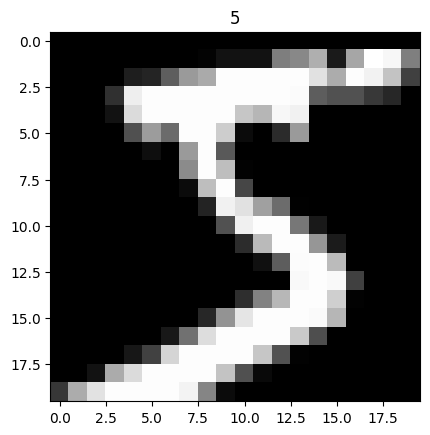

In [15]:
plt.imshow(img0.view(20, 20), cmap="gray")
plt.title(label0)
plt.show()

## 7. DataLoader — batch_size=64

배치 shape은 `(B, C, H, W)`입니다. `squeeze`로 크기 1인 채널 축을 제거해 `(20, 20)`으로 만든 뒤 그립니다.

배치 shape: torch.Size([64, 1, 20, 20])
한 장 shape: torch.Size([1, 20, 20])
정답 묶음 shape: torch.Size([64])


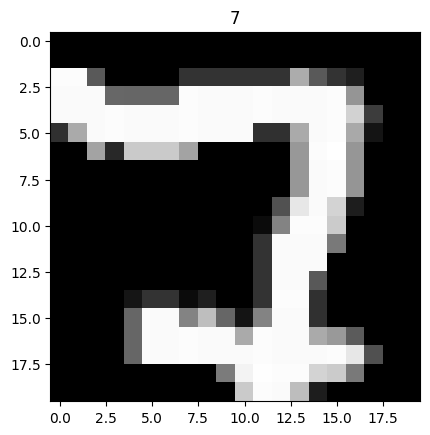

In [16]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

train_features, train_labels = next(iter(train_loader))
print("배치 shape:", train_features.shape)  # (64, 1, 20, 20)
print("한 장 shape:", train_features[0].shape)
print("정답 묶음 shape:", train_labels.shape)

f1 = train_features[0].squeeze()  # (1,20,20)에서 크기 1인 채널 축 제거 → (20,20), imshow용
l1 = train_labels[0] # 정답 레이블
plt.imshow(f1, cmap="gray") # f1을 흑백 색상 맵으로 그립니다.
plt.title(int(l1)) # l1을 제목으로 추가
plt.show() # 그래프를 표시

---

이론 복습: [`../session05.md`](../session05.md) · Dataset 복습: [`04_custom_dataset.ipynb`](./04_custom_dataset.ipynb)